# Encoding features and dealing with missing values

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# import data

harmonized_features2010 = pd.read_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2010.pkl")
harmonized_features2013 = pd.read_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2013.pkl")
harmonized_features2016 = pd.read_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2016.pkl")

In [3]:
# Remove all rows that contain NaN values in the "Distance to the nearest drinking water source (meters)" (this will be 74 rows)
harmonized_features2010 = harmonized_features2010.dropna(subset=["Distance to the nearest drinking water source (meters)"])
harmonized_features2013 = harmonized_features2013.dropna(subset=["Distance to the nearest drinking water source (meters)"])
harmonized_features2016 = harmonized_features2016.dropna(subset=["Distance to the nearest drinking water source (meters)"])

In [ ]:
# Convert to numeric
for df in [harmonized_features2010, harmonized_features2013, harmonized_features2016]:
    col = "Amount paid to private water vendor last 7 days"
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(0)

In [ ]:
# Impute 0s for NaNs in the "Distance to the nearest drinking water source (meters)" column
harmonized_features2010["Amount paid to private water vendor last 7 days"] = harmonized_features2010["Amount paid to private water vendor last 7 days"].fillna(0)
harmonized_features2013["Amount paid to private water vendor last 7 days"] = harmonized_features2013["Amount paid to private water vendor last 7 days"].fillna(0)
harmonized_features2016["Amount paid to private water vendor last 7 days"] = harmonized_features2016["Amount paid to private water vendor last 7 days"].fillna(0)

# This will be applid to roughly 75% of data across all years

In [5]:
# Impute 0s for NaNs in the "Amount paid on electricity in last 4 weeks" column
harmonized_features2010["Amount paid on electricity in last 4 weeks"] = harmonized_features2010["Amount paid on electricity in last 4 weeks"].fillna(0)
harmonized_features2013["Amount paid on electricity in last 4 weeks"] = harmonized_features2013["Amount paid on electricity in last 4 weeks"].fillna(0)
harmonized_features2016["Amount paid on electricity in last 4 weeks"] = harmonized_features2016["Amount paid on electricity in last 4 weeks"].fillna(0)

# This will be applid to roughly 80-95% of data across all years

In [ ]:
# Impute "No" into the Able to write a simple letter column based on the Able to read a simple written note column

def impute_writing_ability(df):
    """
    Fills missing values in 'Able to write a simple letter' with 'No' 
    if the corresponding 'Able to read a simple written note' is also 'No'.
    """
    read_col = "Able to read a simple written note"
    write_col = "Able to write a simple letter"
    
    if read_col not in df.columns or write_col not in df.columns:
        raise ValueError("Required columns not found in DataFrame.")
    
    mask = (df[write_col].isna()) & (df[read_col] == "No")
    df.loc[mask, write_col] = "No"
    
    return df

harmonized_features2010 = impute_writing_ability(harmonized_features2010)
harmonized_features2013 = impute_writing_ability(harmonized_features2013)
harmonized_features2016 = impute_writing_ability(harmonized_features2016)

# This will be applied to 30-50% of data across all years

In [ ]:
# Impute highest class successfully attaind based on school attendance

def impute_school_attainment(df):
    """
    Imputes 'None' into 'Highest class succesfully attained in school' 
    if the respondent has never been to school and the field is missing.
    Works with categorical dtype.
    """
    attend_col = "Ever been to school"
    class_col = "Highest class succesfully attained in school"

    if attend_col not in df.columns or class_col not in df.columns:
        raise ValueError("Required columns not found in DataFrame.")
    
    # Ensure 'None' is in the category list if it's categorical
    if pd.api.types.is_categorical_dtype(df[class_col]):
        if "None" not in df[class_col].cat.categories:
            df[class_col] = df[class_col].cat.add_categories(["None"])
    
    # Impute 'None' where relevant
    mask = (df[attend_col] == "No") & (df[class_col].isna())
    df.loc[mask, class_col] = "None"

    return df

harmonized_features2010 = impute_school_attainment(harmonized_features2010)
harmonized_features2013 = impute_school_attainment(harmonized_features2013)
harmonized_features2016 = impute_school_attainment(harmonized_features2016)

# This will be applied to 25-40% of data across all years

In [ ]:
# Drop the "Highest school diploma or certificate obtained" column since we already have an educational level column" and the "Attended school in the last 12 months" since it contains too many NaN values for the 2013 dataframe
for df in [harmonized_features2010, harmonized_features2013, harmonized_features2016]:
    df.drop(columns=["Highest school diploma or certificate obtained", "Attended school in the last 12 months"], inplace=True)

In [ ]:
# Drop all rows that contain NaN values in the "Highest class succesfully attained in school" column
harmonized_features2010 = harmonized_features2010.dropna(subset=["Highest class succesfully attained in school"])

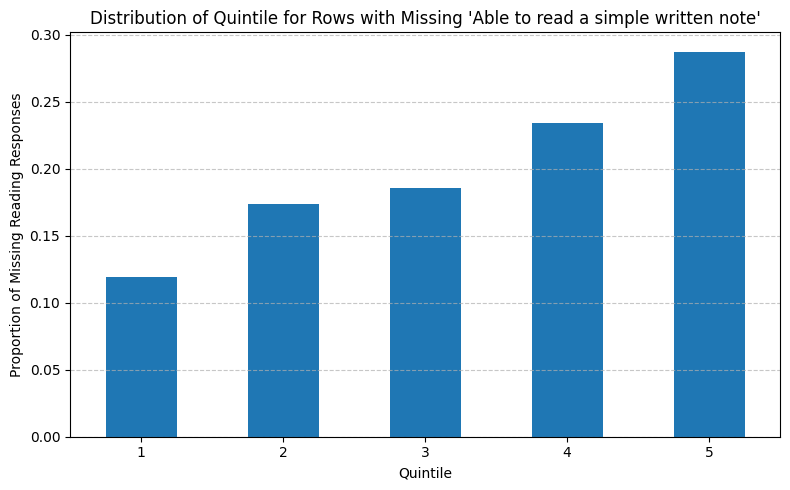

In [ ]:
# CHECK IF DELETING NANS IN THE "Highest class successfully attained in school" COLUMN WILL INTRODUCE BIAS

# Filter rows with missing reading ability
subset = harmonized_features2010[harmonized_features2010["Able to read a simple written note"].isna()]

# Plot the distribution of 'quintile'
plt.figure(figsize=(8, 5))
subset['Quintile'].value_counts(normalize=True).sort_index().plot(kind='bar')

plt.title("Distribution of Quintile for Rows with Missing 'Able to read a simple written note'")
plt.xlabel("Quintile")
plt.ylabel("Proportion of Missing Reading Responses")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [13]:
# Drop all NaN values in the three 

cols_to_check = [
    "Able to read a simple written note",
    "Able to write a simple letter",
    "Able to do a written calculation"
]

harmonized_features2010 = harmonized_features2010.dropna(subset=cols_to_check)
harmonized_features2013 = harmonized_features2013.dropna(subset=cols_to_check)
harmonized_features2016 = harmonized_features2016.dropna(subset=cols_to_check)

In [ ]:
# Rule based imputation 

def impute_computer_confidence(df):
    read_col = "Able to read a simple written note"
    write_col = "Able to write a simple letter"
    comp_col = "Confidence to use computer"
    
    # Add needed categories if the column is categorical
    if pd.api.types.is_categorical_dtype(df[comp_col]):
        for val in ["Not literate", "No"]:
            if val not in df[comp_col].cat.categories:
                df[comp_col] = df[comp_col].cat.add_categories([val])

    # Rule 1: Can't read → Not literate
    mask_read = (df[comp_col].isna()) & (df[read_col] == "No")
    df.loc[mask_read, comp_col] = "Not literate"

    # Rule 2: Can't write → No (but only if it's still NaN)
    mask_write = (df[comp_col].isna()) & (df[write_col] == "No")
    df.loc[mask_write, comp_col] = "No"

    return df

harmonized_features2010 = impute_computer_confidence(harmonized_features2010)
harmonized_features2013 = impute_computer_confidence(harmonized_features2013)
harmonized_features2016 = impute_computer_confidence(harmonized_features2016)

# This will be applied to 50% for the 2010 dataframe and 0% for the 2013 and 2016 dataframes

/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/1920799588.py:7: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[comp_col]):
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/1920799588.py:7: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[comp_col]):
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/1920799588.py:7: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[comp_col]):


In [ ]:
# Rule based imputation - if the household doesn't own any land, havest any crops and have no livestock then the number for the value should be 0

cols_to_fill = [
    "Total surface area of land owned",
    "Total value of large crop harvest",
    "Total value of livestock"
]

for df in [harmonized_features2010, harmonized_features2013, harmonized_features2016]:
    df[cols_to_fill] = df[cols_to_fill].fillna(0)

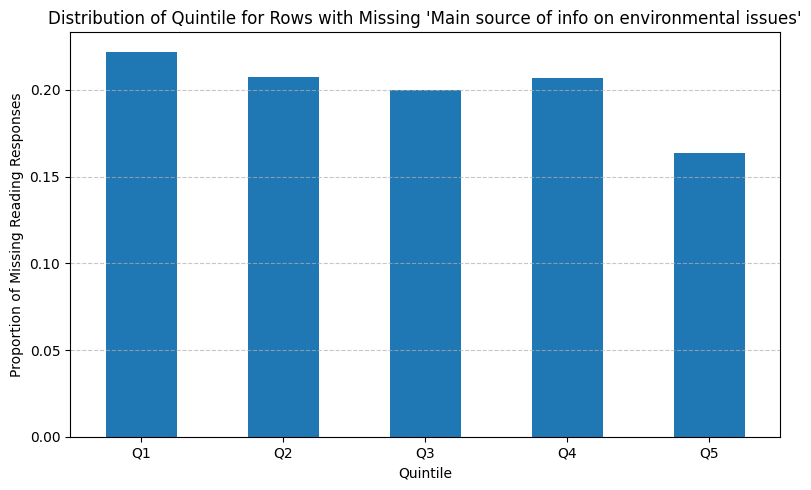

In [ ]:
# CHECK IF DELETING NANS IN THE "Main source of info on environmental issues" COLUMN WILL INTRODUCE BIAS

# Filter rows with missing reading ability
subset = harmonized_features2016[harmonized_features2016["Main source of info on environmental issues"].isna()]

# Plot the distribution of 'quintile'
plt.figure(figsize=(8, 5))
subset['Quintile'].value_counts(normalize=True).sort_index().plot(kind='bar')

plt.title("Distribution of Quintile for Rows with Missing 'Main source of info on environmental issues'")
plt.xlabel("Quintile")
plt.ylabel("Proportion of Missing Reading Responses")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [18]:
for df in [harmonized_features2010, harmonized_features2013, harmonized_features2016]:
    df.dropna(subset=["Main source of info on environmental issues"], inplace=True)

In [ ]:
def impute_internet_connection(df):
    internet_col = "Internet connection at home"
    mobile_col = "Has a mobile telephone"
    
    # Ensure consistent lowercase comparison
    mobile_col_clean = df[mobile_col].astype(str).str.lower()
    internet_isna = df[internet_col].isna()
    mobile_is_no = mobile_col_clean == "no"
    
    # If categorical, ensure "No" is an allowed value
    if pd.api.types.is_categorical_dtype(df[internet_col]):
        if "No" not in df[internet_col].cat.categories:
            df[internet_col] = df[internet_col].cat.add_categories(["No"])
    
    # Apply imputation
    df.loc[internet_isna & mobile_is_no, internet_col] = "No"
    
    return df

harmonized_features2010 = impute_internet_connection(harmonized_features2010)
harmonized_features2013 = impute_internet_connection(harmonized_features2013)
harmonized_features2016 = impute_internet_connection(harmonized_features2016)

/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/4073036771.py:11: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[internet_col]):
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/4073036771.py:11: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[internet_col]):
/var/folders/n5/_f2xjmkj39gb7s0th_6lyk9w0000gn/T/ipykernel_15280/4073036771.py:11: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(df[internet_col]):


In [ ]:
# Create a new Quintile column based on Equivalenced consumption for the 2023 dataframe since it doesn't exist (can be used for robustness checks)
harmonized_features2013["Quintile"] = pd.qcut(harmonized_features2013["Equivalenced consumption"], q=5, labels=[1, 2, 3, 4, 5])

In [22]:
# Save harmonized features with no missing values
harmonized_features2010.to_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2010_clean.pkl")
harmonized_features2013.to_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2013_clean.pkl")
harmonized_features2016.to_pickle("/Users/gianjaeger/Desktop/Applied Machine Learning Project/harmonized_features2016_clean.pkl")

# One hot-encoding and ordinal encoding

In [23]:
harmonized_features2010 = harmonized_features2010.drop(columns=[
    'Province',
    'District (also stratum for SE calculation)',
    'Final weight of household',
    'Cluster'
])

In [24]:
harmonized_features2013 = harmonized_features2013.drop(columns=[
    'Province',
    'District (also stratum for SE calculation)',
    'Final weight of household',
    'Cluster'
])

In [25]:
harmonized_features2016 = harmonized_features2016.drop(columns=[
    'Province',
    'District (also stratum for SE calculation)',
    'Final weight of household',
    'Cluster'
])

In [26]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

def encode_features(df):
    df = df.copy()

    # Binary Encoding
    binary_cols = {
        "Sex": {"male": 1, "female": 0},
        "Urban/rural 2002": {"urban": 1, "rural": 0},
        "Ever been to school": {"yes": 1, "no": 0},
        "Able to read a simple written note": {"yes": 1, "no": 0},
        "Able to write a simple letter": {"yes": 1, "no": 0},
        "Able to do a written calculation": {"yes": 1, "no": 0},
        "Has a mobile telephone": {"yes": 1, "no": 0},
        "Internet connection at home": {"yes": 1, "no": 0},
        "Household reported owning any land": {"yes": 1, "no": 0},
        "Household harvested any large crops in last 12 months": {"yes": 1, "no": 0},
        "Household raised any livestock in last 12 months": {"yes": 1, "no": 0}
    }

    for col, mapping in binary_cols.items():
        df[col] = df[col].str.strip().str.lower().map(mapping)

    # Ordinal Encoding (with "None" added for non-schooled individuals)
    ordinal_cols = {
    "Highest class succesfully attained in school": [
        "None", 
        "Pre-primary",
        "Not complete P1",
        "Primary 1", "Primary 2", "Primary 3", "Primary 4", "Primary 5", "Primary 6,7,8",
        "Post primary 1", "Post primary 2", "Post primary 3", "Post primary 4", "Post primary 5", "Post primary 6,7,8",
        "Not complete Sec S1",
        "Secondary 1", "Secondary 2", "Secondary 3", "Secondary 4", "Secondary 5", "Secondary 6",
        "Not complete Vocat S1",
        "Not complete University 1",
        "University 1", "University 2", "University 3", "University 4", "University 5", "University 6", "University 7",
        "Don't Know"
    ],
    "Confidence to use computer": [
        "Not literate", "No", "Yes"
    ]
}

    for col, order in ordinal_cols.items():
        encoder = OrdinalEncoder(categories=[order], handle_unknown="use_encoded_value", unknown_value=-1)
        df[col] = encoder.fit_transform(df[[col]])

    # Explicit One-Hot Encoding
    one_hot_cols = [
        "Marital status", "Place of birth", "Health insurance",
        "Type of habitat", "Type of dwelling", "Owner of the dwelling",
        "Current occupancy status", "Main source of drinking water",
        "Main source of home lighting", "Primary source of cooking fuel",
        "Mode of rubbish disposal", "Type of toilet household use",
        "Main source of info on environmental issues",
        "Main construction material of exterior wall",
        "Main roofing material for dwelling",
        "Main floor material for dwelling"
    ]

    df = pd.get_dummies(df, columns=one_hot_cols, drop_first=False, dtype=int)

    # No changes for numeric variables:
    numeric_cols = [
        "Age (Years)", "Household size", "Number of kids",
        "Total surface area of land owned", "Total value of large crop harvest",
        "Total value of livestock", "Distance to the nearest drinking water source (meters)",
        "Amount paid to private water vendor last 7 days",
        "Amount paid on electricity in last 4 weeks", "Equivalenced consumption"
    ]
    # These columns remain untouched.

    return df

In [27]:
harmonized_features2010_encoded = encode_features(harmonized_features2010)
harmonized_features2013_encoded = encode_features(harmonized_features2013)
harmonized_features2016_encoded = encode_features(harmonized_features2016)

In [28]:
# Columns that are causing issues
problem_cols = [
    'Place of birth_99.0',
    'Place of birth_Others',
    'Place of birth_neighboring countries'
]

# Drop from all three datasets (ignore errors if not present)
harmonized_features2010_encoded = harmonized_features2010_encoded.drop(columns=problem_cols, errors='ignore')

In [29]:
col = 'Distance to the nearest drinking water source (meters)'
value_to_drop = 'Greater than 9 km'

for df in [harmonized_features2013_encoded]:
    if col in df.columns:
        df.drop(df[df[col] == value_to_drop].index, inplace=True)

In [30]:
missing_col = 'Place of birth_Gkenke'

if missing_col not in harmonized_features2016_encoded.columns:
    harmonized_features2016_encoded[missing_col] = 0

In [31]:
# Define mapping
quintile_map = {
    'Q1': 1,
    'Q2': 2,
    'Q3': 3,
    'Q4': 4,
    'Q5': 5
}

# Replace and convert to numeric
if 'quintile' in harmonized_features2016_encoded.columns:
    harmonized_features2016_encoded['Quintile'] = harmonized_features2016_encoded['Quintile'].replace(quintile_map)
    harmonized_features2016_encoded['Quintile'] = pd.to_numeric(harmonized_features2016_encoded['Quintile'], errors='coerce')

In [32]:
harmonized_features2010_encoded.to_pickle("harmonized_features2010_encoded.pkl")
harmonized_features2013_encoded.to_pickle("harmonized_features2013_encoded.pkl")
harmonized_features2016_encoded.to_pickle("harmonized_features2016_encoded.pkl")

print("✅ Harmonized feature files saved to current working directory.")

✅ Harmonized feature files saved to current working directory.


----